# Neural Black-Scholes solvers - A comparison

This sections presents the implementation of two neural solvers of the Black-Scholes equation (BS) written as a BSDE and solved with a neural solver under the Deep BSDE protocol. This notebook finds the fair price of an geometric basket option. It is used because it has a closed form solution and the methods can easily be compared. Altough additional payoff functions (terminal conditions) are includeed and can be swapped, altough these lack exact solution. The basket option is assumened to be uncorrelated (for simplicity). The two methods compared is the vanilla single point Deep BSDE with subnets and the adjusted shared net single point Deep BSDE. 

The notebook investigates how model parameters grow as a function of $N$, training times for such networks, accuracy under a fixed budget and convergence time for a tolerance. 

In [93]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

Consider the multidimensional BS, expressed as 
\begin{equation}
    \partial_t u + \tfrac{1}{2}\operatorname{Tr}\!\big(\sigma\sigma^{\top}\nabla^2 u\big) + \mu\cdot\nabla u - ru = 0,
\qquad u(T,S) = g(S) = \Big((\Pi_{i=1} S^i)^{1/d} - K\Big)^{+}
\end{equation}
The SDE can be defined as 
\begin{equation}
    dS_t = \operatorname{diag}(r-q)\,S_t\,dt + \operatorname{diag}(S_t)\operatorname{diag}(\sigma)\,dW_t,
\end{equation}
In this implementation we consider $d = 100$, $K = 100$, $\xi = 100$, $\sigma = 1$, $T=1$, $t = 0$, $N = 20$, $\Delta t = T/N$, $r = 0.05$ and $q = 0$ for the Deep BSDE solvers.

The exact solution for the geometric basket call is defined as

In [94]:
from scipy.stats import norm

def geo_basket_call(S0, K, r, q, sigma, rho, T):
    """S0, q, sigma: arrays of shape (d,); rho: (d, d) correlation matrix."""
    S0, q, sigma = map(np.asarray, (S0, q, sigma))
    d = len(S0)
    sig_G2 = sigma @ rho @ sigma / d**2                      # variance of the log geometric mean
    mu_G = np.mean(np.log(S0) + (r - q - 0.5 * sigma**2) * T)
    F = np.exp(mu_G + 0.5 * sig_G2 * T)                      # forward of the geometric mean
    s = np.sqrt(sig_G2 * T)
    d1 = (np.log(F / K) + 0.5 * s**2) / s
    d2 = d1 - s
    return np.exp(-r * T) * (F * norm.cdf(d1) - K * norm.cdf(d2))

The stochastic process can be integrated as $Y_{n+1} = Y_n - f(t_n, S_n, Y_n, Z_n)\,\Delta t + Z_n^\top \Delta W_n = Y_n + r\,Y_n\,\Delta t + Z_n^\top \Delta W_n$

Since $f = -ru \to f = - r Y_n$, and familiarly $Z_n = \sigma^{\top} \nabla u(n, X_n)$

Both methods use the same path sampling. Since $X_t$ and $W_t$ do not require a computational graph and are not used to update the network, the can be sampled all at once (for a batch) and seperatly, outside the network.

In [95]:
def sample_paths(xi, bs, d, N, dt, r=0.05, q=0.0, sigma=0.2):
    dW = np.sqrt(dt) * np.random.randn(bs, N, d)
    log_incr = (r - q - 0.5 * sigma**2) * dt + sigma * dW
    X = np.empty((bs, N + 1, d))
    X[:, 0] = xi
    X[:, 1:] = xi * np.exp(np.cumsum(log_incr, axis=1))
    return torch.tensor(X, dtype=torch.float32), torch.tensor(dW, dtype=torch.float32)


r = 0.05
def fun(Y):
    return -r*Y

K = 100.0
def g_geo(x):  # geometric basket call (closed form exists)
    return (x.log().mean(-1).exp() - K).clamp(min=0)

def g_ari(x):
    pass

In the original Deep BSDE network, each increment in time corresponds to its own neural network estimating $Z_t$. So called subnets to the full NN and are represented by a module. The full net and consequently each subnet is updated after each batch of 64-128 paths are run. The paths are run forward in time and starts at $Y_0 = \theta_y$ (a trainable parameter).

The shared network metyhodology instead implements one shared NN that is continously updated under the same loss function. This network should be more sparse, but the question is if it can match performance of the original Deep BSDE under a leaner computational budget.


The loss funtion is familiarly
\begin{equation}
    \mathcal{L}(\theta) = \frac{1}{M} \sum_{m = 1}^M |Y_N^{(m)} - g(X_N^{(m)})|^2 = \mathbb{E}[|Y_T - g(X_T)|^2]
\end{equation}


In [96]:
class SubNet(nn.Module):
    """ Subnet for each time increment Z_t, takes dimension and width as arguments.
    Typically, width = d + 10
    """
    def __init__(self, d, width):
        super().__init__()
        self.net = nn.Sequential(nn.BatchNorm1d(d),
            nn.Linear(d, width),
            nn.BatchNorm1d(width),
            nn.ReLU(),
            nn.Linear(width, width),
            nn.BatchNorm1d(width),
            nn.ReLU(),
            nn.Linear(width, d),
        )
    def forward(self, x):
        return self.net(x)


class YZnet(nn.Module):
    def __init__(self, d, dt, N, f, y0_init=(0., 1.)):
            super().__init__()
            self.N, self.dt, self.f = N, dt, f
            self.y0 = nn.Parameter(torch.empty(1).uniform_(*y0_init))
            self.z0 = nn.Parameter(torch.empty(d).uniform_(-1,1))
            self.subnets = nn.ModuleList([SubNet(d, d+10) for _ in range(N-1)])
    def forward(self, X, dW):
        M = X.shape[0]
        y = self.y0.expand(M)
        z = self.z0.expand(M, -1)
        for n in range(self.N):
            t = n*self.dt
            y = y - self.f(y) * self.dt + (z*dW[:,n]).sum(-1)
            if n < self.N-1:
                z = self.subnets[n](X[:, n + 1])
        return y


In [97]:
class ZNet(nn.Module):
    """One network Z(t, x) shared over all time steps (Chan-Wai-Nam et al., 'FC Merged')."""
    def __init__(self, d, width, T, x_mean, x_std):
        super().__init__()
        self.T = T
        self.register_buffer("x_mean", torch.as_tensor(x_mean, dtype=torch.float32))
        self.register_buffer("x_std", torch.as_tensor(x_std, dtype=torch.float32))
        self.net = nn.Sequential(
            nn.Linear(d + 1, width), nn.ELU(),
            nn.Linear(width, width), nn.ELU(),
            nn.Linear(width, d),
        )

    def forward(self, t, x):
        # standardizes input, instead of batchnorm. 
        x = (x - self.x_mean) / self.x_std
        t = torch.full_like(x[:, :1], 2 * t / self.T - 1)   # time scaled to [-1, 1]
        return self.net(torch.cat([x, t], dim=1))


class YZnet_shared(nn.Module):
    def __init__(self, d, dt, N, f, x_mean, x_std, y0_init=(0., 1.)):
        super().__init__()
        self.N, self.dt, self.f = N, dt, f
        self.y0 = nn.Parameter(torch.empty(1).uniform_(*y0_init))
        self.z0 = nn.Parameter(torch.empty(d).uniform_(-1, 1))
        self.znet = ZNet(d, d + 10, N * dt, x_mean, x_std)

    def forward(self, X, dW):
        M = X.shape[0]
        y = self.y0.expand(M)
        z = self.z0.expand(M, -1)
        for n in range(self.N):
            y = y - self.f(y) * self.dt + (z * dW[:, n]).sum(-1)
            if n < self.N - 1:
                # Model now takes t as a parameter as well since it is not discretized in subnets 
                z = self.znet((n + 1) * self.dt, X[:, n + 1])
        return y

Here, the model and optimizer is set up. In this case ADAM is used, but SGD could also be used as in the original paper.

In [98]:
T = 1.0
N = 20
dt = T/N
d = 100
S0 = np.full(d, 100.0)

X_pilot, _ = sample_paths(xi=S0, bs=10_000, d=d, N=N, dt=dt)   # X: (M, N+1, d)
x_mean = X_pilot.mean(dim=(0, 1))
x_std  = X_pilot.std(dim=(0, 1)) + 1e-8

orig_model   = YZnet(d=d, dt=dt, N=N, f=fun)
merged_model = YZnet_shared(d=d, dt=dt, N=N, f=fun, x_mean=x_mean, x_std=x_std)

def make_opt(model, lr_y0=1e-2, lr_z=1e-3):
    """Separate learning rates: a larger one for the scalar y0, a smaller one for the Z networks."""
    y0_params = [model.y0]
    z_params  = [p for name, p in model.named_parameters() if name != "y0"]
    return torch.optim.Adam([
        {"params": y0_params, "lr": lr_y0},
        {"params": z_params,  "lr": lr_z},
    ])

orig_opt   = make_opt(orig_model)
merged_opt = make_opt(merged_model)

The loss and train functions are defined

In [99]:
def loss_fn(model, X, dW):
    return ((model(X, dW) - g_geo(X[:, -1]))**2).mean()

def train(model, opt, batch_size, n_iter, d, N, dt, xi, verbose: bool = True):
    y0_hist = np.zeros(n_iter)
    loss_hist = np.zeros(n_iter)
    for i in range(n_iter):
        opt.zero_grad()

        X, dW = sample_paths(xi, batch_size, d=d, N=N, dt=dt )

        loss = loss_fn(model, X, dW)
        loss.backward()
        opt.step()

        loss_hist[i] = loss.item()
        y0_hist[i] = model.y0.item()
        
        if verbose and i % 100 == 0:
            print(f"iter {i:5d} | loss {loss_hist[i]:.4f} | Y0 {y0_hist[i]:.4f}")
    return loss_hist, y0_hist

def train_tol(model, opt, batch_size, tol, d, N, dt, xi, exact,
              patience=5, max_iter=5000, verbose: bool = True):

    y0_hist, loss_hist = [], []
    count = 0
    n_conv = None

    for n_iter in range(1, max_iter + 1):
        opt.zero_grad()
        X, dW = sample_paths(xi, batch_size, d=d, N=N, dt=dt)
        loss = loss_fn(model, X, dW)
        loss.backward()
        opt.step()

        y0 = model.y0.item()
        loss_hist.append(loss.item())
        y0_hist.append(y0)

        # Count only consecutive iterations inside the tolerance band
        count = count + 1 if abs(y0 - exact) < tol else 0
        if count >= patience:
            n_conv = n_iter - patience + 1   # first iteration of the in-band run
            break

        if verbose and n_iter % 100 == 0:
            print(f"iter {n_iter:5d} | loss {loss_hist[-1]:.4f} | Y0 {y0_hist[-1]:.4f}")

    if verbose:
        msg = f"converged at iter {n_conv}" if n_conv else f"did not converge in {max_iter} iters"
        print(msg + f" | Y0 {y0_hist[-1]:.4f} | exact {exact:.4f}")
    return loss_hist, y0_hist, n_conv


For a geometric basket call the exact price can be found

In [100]:
price = geo_basket_call(S0=np.full(d, 100.0), K=100.0, r=0.05, q=np.zeros(d),
                        sigma=np.full(d, 0.2), rho=np.eye(d), T=1.0)

For comparison, the MC method (established in other notebooks) is implemented. Note that since there is no discretization error, here $N=1$ for MC

Now the model can be trained

In [101]:

orig_loss_hist, orig_y0_hist = train(model=orig_model, opt=orig_opt, batch_size=128, n_iter=500, d=d, N=N, dt=dt, xi=S0)
print(f"Y0 = {orig_model.y0.item():.4f}, exact u(0, xi) = {price:.4f}")

merged_loss_hist, merged_y0_hist = train(model=merged_model, opt=merged_opt, batch_size=128, n_iter=500, d=d, N=N, dt=dt, xi=S0)
print(f"Y0 = {merged_model.y0.item():.4f}, exact u(0, xi) = {price:.4f}")


iter     0 | loss 29.0481 | Y0 0.3320
iter   100 | loss 15.4956 | Y0 1.2454
iter   200 | loss 17.6918 | Y0 1.9709
iter   300 | loss 11.8069 | Y0 2.4300
iter   400 | loss 10.6286 | Y0 2.7000
Y0 = 2.8510, exact u(0, xi) = 2.9719
iter     0 | loss 14.4028 | Y0 0.9612
iter   100 | loss 4.6477 | Y0 1.8427
iter   200 | loss 2.6066 | Y0 2.4490
iter   300 | loss 1.5952 | Y0 2.7740
iter   400 | loss 1.3642 | Y0 2.9137
Y0 = 2.9519, exact u(0, xi) = 2.9719


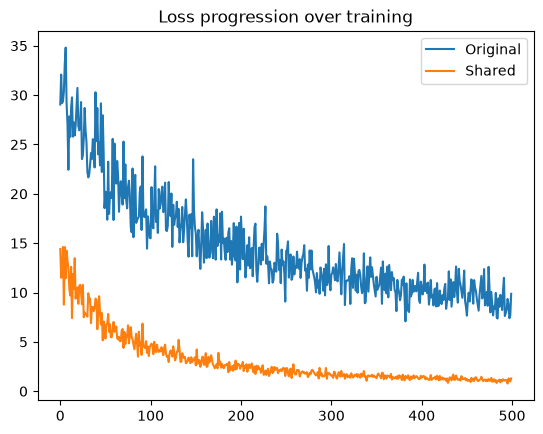

In [102]:
plt.plot(orig_loss_hist, label = "Original")
plt.plot(merged_loss_hist, label = "Shared")
plt.title("Loss progression over training")
plt.legend()
plt.show()

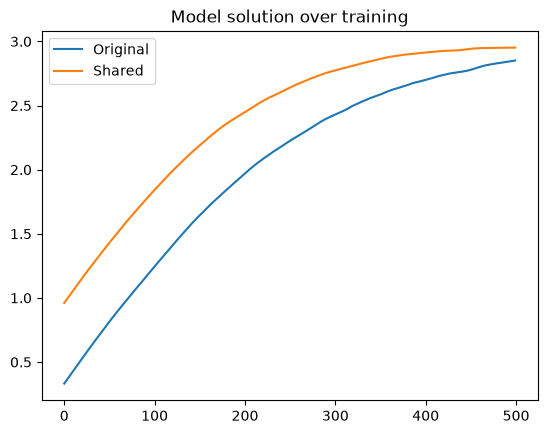

In [103]:
plt.plot(orig_y0_hist, label = 'Original')
plt.plot(merged_y0_hist, label = 'Shared')
plt.title("Model solution over training")
plt.legend()
plt.show()

In [104]:
orig_model   = YZnet(d=d, dt=dt, N=N, f=fun)
merged_model = YZnet_shared(d=d, dt=dt, N=N, f=fun, x_mean=x_mean, x_std=x_std)
orig_opt     = make_opt(orig_model)
merged_opt   = make_opt(merged_model)

loss_h, y0_h, n_conv = train_tol(orig_model, orig_opt, batch_size=128, tol=0.02,
                                 d=d, N=N, dt=dt, xi=S0, exact=price)
print(f"Y0 = {orig_model.y0.item():.4f}, exact u(0, xi) = {price:.4f}")

m_loss_h, m_y0_h, m_n_conv = train_tol(merged_model, merged_opt, batch_size=128, tol=0.02,
                                       d=d, N=N, dt=dt, xi=S0, exact=price)
print(f"Y0 = {merged_model.y0.item():.4f}, exact u(0, xi) = {price:.4f}")


iter   100 | loss 13.2640 | Y0 1.5567
iter   200 | loss 11.8154 | Y0 2.1984
iter   300 | loss 12.8876 | Y0 2.6056
iter   400 | loss 10.5910 | Y0 2.8257
iter   500 | loss 10.2493 | Y0 2.9237
converged at iter 532 | Y0 2.9566 | exact 2.9719
Y0 = 2.9566, exact u(0, xi) = 2.9719
iter   100 | loss 7.9687 | Y0 0.9868
iter   200 | loss 3.8561 | Y0 1.7166
iter   300 | loss 2.3361 | Y0 2.2446
iter   400 | loss 1.6725 | Y0 2.5968
iter   500 | loss 1.0796 | Y0 2.8020
iter   600 | loss 0.8815 | Y0 2.8987
iter   700 | loss 0.6656 | Y0 2.9405
converged at iter 743 | Y0 2.9529 | exact 2.9719
Y0 = 2.9529, exact u(0, xi) = 2.9719


N=  5 | Original |    4.37 s | converged at iter 540 | Y0 2.9251
N=  5 | Shared   |    2.85 s | converged at iter 539 | Y0 2.9253
N= 10 | Original |   10.97 s | converged at iter 552 | Y0 2.9255
N= 10 | Shared   |    5.68 s | converged at iter 541 | Y0 2.9257
N= 20 | Original |   17.51 s | converged at iter 515 | Y0 2.9226
N= 20 | Shared   |   10.56 s | converged at iter 522 | Y0 2.9245
N= 30 | Original |   26.52 s | converged at iter 519 | Y0 2.9231
N= 30 | Shared   |   15.87 s | converged at iter 528 | Y0 2.9237
N= 40 | Original |   38.78 s | converged at iter 568 | Y0 2.9251
N= 40 | Shared   |   21.19 s | converged at iter 539 | Y0 2.9241


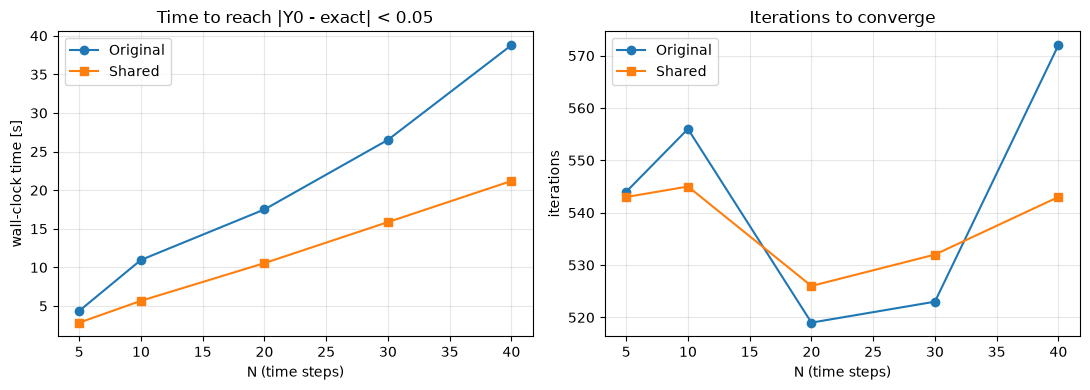

In [ ]:
import time

def make_models(N_, seed=0):
    """Fresh models + optimizers for a given N (pilot stats recomputed for the shared net)."""
    dt_ = T / N_
    X_p, _ = sample_paths(xi=S0, bs=2_000, d=d, N=N_, dt=dt_)
    mean_, std_ = X_p.mean(dim=(0, 1)), X_p.std(dim=(0, 1)) + 1e-8
    torch.manual_seed(seed)
    m_orig = YZnet(d=d, dt=dt_, N=N_, f=fun)
    torch.manual_seed(seed)
    m_shared = YZnet_shared(d=d, dt=dt_, N=N_, f=fun, x_mean=mean_, x_std=std_)
    return {"Original": (m_orig, make_opt(m_orig)), "Shared": (m_shared, make_opt(m_shared))}

Ns_time  = [5, 10, 20, 30, 40]
tol      = 0.02
max_iter = 5000
results  = {"Original": {"time": [], "iters": [], "conv": []},
            "Shared":   {"time": [], "iters": [], "conv": []}}

for N_ in Ns_time:
    for name, (model, opt_) in make_models(N_).items():
        np.random.seed(0)                       # same path stream for both models
        t0 = time.perf_counter()
        _, y0_h, n_conv = train_tol(model, opt_, batch_size=128, tol=tol, d=d, N=N_,
                                    dt=T / N_, xi=S0, exact=price,
                                    max_iter=max_iter, verbose=False)
        elapsed = time.perf_counter() - t0
        results[name]["time"].append(elapsed)
        results[name]["iters"].append(len(y0_h))
        results[name]["conv"].append(n_conv is not None)
        status = f"converged at iter {n_conv}" if n_conv else "NOT converged"
        print(f"N={N_:3d} | {name:8s} | {elapsed:7.2f} s | {status} | Y0 {y0_h[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, marker in [("Original", "o"), ("Shared", "s")]:
    res = results[name]
    for ax, key in zip(axes, ["time", "iters"]):
        ax.plot(Ns_time, res[key], marker=marker, label=name)
        # red ring around runs that hit max_iter without converging
        bad = [i for i, c in enumerate(res["conv"]) if not c]
        if bad:
            ax.plot([Ns_time[i] for i in bad], [res[key][i] for i in bad], "o",
                    mfc="none", mec="red", ms=12, ls="none")

axes[0].set(xlabel="N (time steps)", ylabel="wall-clock time [s]",
            title=f"Time to reach |Y0 - exact| < {tol}")
axes[1].set(xlabel="N (time steps)", ylabel="iterations",
            title="Iterations to converge")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

N=   2 | Original     35,161 | Shared   34,631 | ratio    1.0
N=   5 | Original    140,341 | Shared   34,631 | ratio    4.1
N=  10 | Original    315,641 | Shared   34,631 | ratio    9.1
N=  20 | Original    666,241 | Shared   34,631 | ratio   19.2
N=  40 | Original  1,367,441 | Shared   34,631 | ratio   39.5
N=  60 | Original  2,068,641 | Shared   34,631 | ratio   59.7
N=  80 | Original  2,769,841 | Shared   34,631 | ratio   80.0
N= 100 | Original  3,471,041 | Shared   34,631 | ratio  100.2


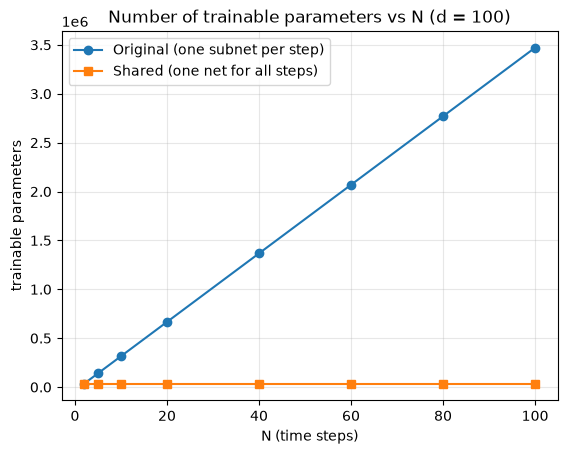

In [107]:
def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Ns = [2, 5, 10, 20, 40, 60, 80, 100]
p_orig, p_shared = [], []
for N_ in Ns:
    dt_ = T / N_
    p_orig.append(n_params(YZnet(d=d, dt=dt_, N=N_, f=fun)))
    p_shared.append(n_params(YZnet_shared(d=d, dt=dt_, N=N_, f=fun, x_mean=x_mean, x_std=x_std)))

for N_, po, ps in zip(Ns, p_orig, p_shared):
    print(f"N={N_:4d} | Original {po:>10,d} | Shared {ps:>8,d} | ratio {po/ps:6.1f}")

plt.plot(Ns, p_orig, "o-", label="Original (one subnet per step)")
plt.plot(Ns, p_shared, "s-", label="Shared (one net for all steps)")
plt.xlabel("N (time steps)")
plt.ylabel("trainable parameters")
plt.title(f"Number of trainable parameters vs N (d = {d})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Discussion / comment

Swapping the original architecture composed of subnets for each time step grows the size of the network as $N$ grows, this in turn demands compute resorces as larger nets take more iterations and longer time to train and update, this creates a negative compute-time spiral. Instead the shared network is introduced which does not grow with the number of timesteps $N$ but is fixed (and has fewer parameters than the original version for every $N$ except $N = 1$). The results from the notebook suggest that the shared model is equally capable (at least in the tests performed here). For a given tolerance the model training time seems to grow linearly with $N$ and is nearly around half the time for the corresponding subnet model. 